# Graph Environment Analysis Notebook

This notebook analyzes CSV results from graph-based simulations comparing **empathic** vs **non-empathic** agents.

## Configuration (aligned with main_graph.py / config.py)
- **Agents**: 5
- **Pool**: Initial 50, max 100
- **Regeneration**: constant, rate=0.2
- **Graph**: Dynamic (emerging connections)
- **Empathic Penalty**: -1.0
- **Empathy Alpha**: 0.5 (empathic) vs 0.0 (non-empathic)

## Metrics Analyzed
- **Depletion Step**: Step at which pool first reaches 0
- **Avg Pool During Episode**: Mean pool level throughout episode
- **Pool Remaining**: Pool level at episode end
- **Gini Coefficients**: Inequality in consumption and satisfaction
- **Total Consumption**: Resources consumed per episode
- **Empathic Penalty Events**: Number of empathic penalties triggered
- **Graph Density / Avg Degree**: Graph connectivity at episode end
- **Mean Reward**: Average of total_reward across agents

## File Format
`graph_results_<sim>_<episodes>_agents<n>_pool<p>_regen<mode>_graph<type>_alpha<alpha>_<params>_<random>_<suffix>.csv`

# Imports

In [1]:
import numpy as np
import pandas as pd
import os
import re
import matplotlib.pyplot as plt
import seaborn as sns
import ast
from scipy import stats

# General variables

## Filenames

In [2]:
# Define the pattern for graph simulation filenames
# Format: graph_results_<sim>_<episodes>_agents<n>_pool<p>_regen<mode>_graph<type>_alpha<alpha>_
#         <lr>_<gamma>_<epsilon>_<epsilon_decay>_<epsilon_min>_<batch>_<hidden>_<update>_<random>_<suffix>.csv

graph_filename_pattern = re.compile(
    r"graph_results_(?P<simulation_index>\d{3})_(?P<episodes>\d+)_"
    r"agents(?P<num_agents>\d+)_"
    r"pool(?P<initial_pool>\d+)_"
    r"regen(?P<regeneration_mode>\w+)_"
    r"graph(?P<graph_type>\w+)_"
    r"alpha(?P<alpha>[\d.]+)_"
    r"(?P<learning_rate>[\d.]+)_(?P<gamma>[\d.]+)_(?P<epsilon>[\d.]+)_(?P<epsilon_decay>[\d.]+)_(?P<epsilon_min>[\d.]+)_"
    r"(?P<batch_size>\d+)_(?P<hidden_size>\d+)_(?P<update_target_every>\d+)_"
    r"(?P<random_suffix>\d{6})_(?P<suffix>[a-zA-Z_]+)\.csv"
)

FILENAME_PATTERNS = [graph_filename_pattern]

FILENAME_PATTERNS_PAIR = [
    ("graph", graph_filename_pattern)
]

# Functions

## CSV processing

### Parameter recovery from filenames

In [3]:
def parse_results_filenames(folder_path: str, filename_patterns=None) -> pd.DataFrame:
    """
    Scans a folder for result filenames and extracts simulation parameters into a DataFrame.

    Args:
        folder_path (str): Path to the folder containing result CSV files.
        filename_patterns (list): List of compiled regex patterns to match filenames.
                                  If None, use global FILENAME_PATTERNS.

    Returns:
        pd.DataFrame: DataFrame containing parsed parameters from filenames.
    """
    if filename_patterns is None:
        filename_patterns = FILENAME_PATTERNS

    data = []

    for filename in os.listdir(folder_path):
        if not filename.endswith(".csv"):
            continue

        matched = False
        for pattern in filename_patterns:
            match = pattern.match(filename)
            if match:
                file_data = match.groupdict()
                file_data["filename"] = filename
                data.append(file_data)
                matched = True
                break

        if not matched:
            print(f"Warning: filename did not match any pattern: {filename}")

    if not data:
        print("No matching filenames found.")
        return pd.DataFrame()

    df = pd.DataFrame(data)

    for col in df.columns:
        if col not in {"filename", "suffix", "regeneration_mode", "graph_type"}:
            try:
                df[col] = pd.to_numeric(df[col])
            except Exception:
                pass

    return df

In [4]:
def print_unique_parameter_values(df: pd.DataFrame, exclude: list = None):
    """
    Print a table with parameter names and their unique values.

    Args:
        df (pd.DataFrame): The input DataFrame with simulation parameters.
        exclude (list): Optional list of column names to exclude.
    """
    if exclude is None:
        exclude = ['filename', 'simulation_index']

    param_cols = [col for col in df.columns if col not in exclude]

    summary = {
        "parameter": [],
        "unique_values": []
    }

    for col in param_cols:
        summary["parameter"].append(col)
        summary["unique_values"].append(sorted(df[col].dropna().unique().tolist()))

    summary_df = pd.DataFrame(summary)
    print(summary_df)

### Aggregation of csv

In [5]:
def aggregate_results_by_suffix(folder_path: str, target_suffix: str, environment_type: str = None) -> pd.DataFrame:
    '''
    Aggregate CSV files by suffix (e.g., "episode_summary").

    Args:
        folder_path: Path to the folder containing the CSV files
        target_suffix: Ending name of the CSV => "episode_summary" or "step_data"
        environment_type: "graph" (optional filter)

    Returns:
        Aggregated dataframe
    '''
    all_data = []

    for filename in os.listdir(folder_path):
        if not filename.endswith(".csv"):
            continue

        for source_type, pattern in FILENAME_PATTERNS_PAIR:
            if environment_type and source_type.lower() != environment_type.lower():
                continue

            match = pattern.match(filename)
            if match:
                metadata = match.groupdict()
                if metadata.get("suffix", "").strip() == target_suffix.strip():
                    file_path = os.path.join(folder_path, filename)
                    try:
                        df = pd.read_csv(file_path)
                        for key, value in metadata.items():
                            df[key] = value
                        df["source"] = source_type.lower()
                        all_data.append(df)
                    except Exception as e:
                        print(f"Error reading {filename}: {e}")
                break

    if not all_data:
        print(f"No matching files found for suffix '{target_suffix}' and source '{environment_type}'.")
        return pd.DataFrame()

    final_df = pd.concat(all_data, ignore_index=True)

    for col in final_df.columns:
        if col not in {"suffix", "filename", "source", "regeneration_mode", "graph_type"}:
            try:
                final_df[col] = pd.to_numeric(final_df[col])
            except:
                pass

    filtered_tag = f"_{environment_type.lower()}" if environment_type else ""
    output_filename = f"aggregated_{target_suffix}{filtered_tag}.csv"
    output_path = os.path.join(folder_path, output_filename)
    final_df.to_csv(output_path, index=False)
    print(f"Saved aggregated data to: {output_path}")

    return final_df

## Data analysis

### Learning verification

In [6]:
def windowed_avg_reward(
    df: pd.DataFrame,
    reward_prefix: str = "total_reward_",
    episode_column: str = "episode",
    simulation_id_column: str = "simulation_number",
    window_size: int = 5,
    aggregation_mode: str = "mean",
    plot: bool = False
) -> pd.DataFrame:
    """
    Computes a windowed moving average of rewards per episode across simulations.

    Args:
        df (pd.DataFrame): Input dataframe.
        reward_prefix (str): Prefix of reward columns per agent.
        episode_column (str): Column name for episodes.
        simulation_id_column (str): Column indicating different simulations.
        window_size (int): Window size for moving average.
        aggregation_mode (str): 'mean' for average across agents, 'best' for max reward among agents.
        plot (bool): Whether to plot the result.

    Returns:
        pd.DataFrame: DataFrame with ['episode', 'mean_reward', 'moving_avg'].
    """
    reward_cols = [col for col in df.columns if col.startswith(reward_prefix)]
    if not reward_cols:
        raise ValueError(f"No columns found with prefix '{reward_prefix}'")

    if aggregation_mode == "mean":
        df["aggregated_reward"] = df[reward_cols].mean(axis=1)
    elif aggregation_mode == "best":
        df["aggregated_reward"] = df[reward_cols].max(axis=1)
    else:
        raise ValueError("aggregation_mode must be 'mean' or 'best'")

    episode_avg = (
        df.groupby(episode_column)["aggregated_reward"]
        .mean()
        .reset_index()
        .rename(columns={"aggregated_reward": "mean_reward"})
    )

    episode_avg["moving_avg"] = (
        episode_avg["mean_reward"].rolling(window=window_size, min_periods=1, center=True).mean()
    )

    if plot:
        plt.figure(figsize=(10, 5))
        plt.plot(episode_avg[episode_column], episode_avg["moving_avg"], label=f"Moving Avg ({aggregation_mode})")
        plt.xlabel("Episode")
        plt.ylabel("Reward")
        plt.title(f"{aggregation_mode.capitalize()} Agent Reward (Window={window_size})")
        plt.grid(True)
        plt.legend()
        plt.tight_layout()
        plt.show()

    return episode_avg

### Variable calculation

#### Gini coefficient

In [7]:
def gini_coefficient(arr: np.ndarray) -> float:
    """Compute Gini coefficient of a 1D numpy array."""
    arr = arr.flatten()
    if np.amin(arr) < 0:
        arr = arr - np.amin(arr)
    mean = np.mean(arr)
    if mean == 0:
        return 0.0
    n = len(arr)
    diff_sum = np.sum(np.abs(np.subtract.outer(arr, arr)))
    gini = diff_sum / (2 * n**2 * mean)
    return gini


def parse_value(val):
    if isinstance(val, str):
        try:
            parsed = ast.literal_eval(val)
            if isinstance(parsed, (list, tuple, np.ndarray)):
                return np.array(parsed, dtype=float)
            else:
                return float(parsed)
        except (ValueError, SyntaxError):
            return float(val)
    elif isinstance(val, (list, tuple, np.ndarray)):
        return np.array(val, dtype=float)
    else:
        return float(val)


def compute_gini_for_df(df: pd.DataFrame, prefix: str) -> pd.Series:
    """
    Compute Gini coefficient across columns starting with prefix for each row in df.
    """
    cols = [col for col in df.columns if col.startswith(prefix)]
    if not cols:
        raise ValueError(f"No columns found starting with prefix '{prefix}'")

    def row_gini(row):
        values = []
        for val in row.values:
            parsed_val = parse_value(val)
            if isinstance(parsed_val, np.ndarray):
                values.extend(parsed_val.flatten())
            else:
                values.append(parsed_val)
        values = np.array(values, dtype=float)
        return gini_coefficient(values)

    gini_series = df[cols].apply(row_gini, axis=1)
    return gini_series

#### Efficiency

In [8]:
def compute_efficiency_for_df(df: pd.DataFrame, prefix: str, new_column_name: str) -> pd.DataFrame:
    """
    Compute the average across columns starting with a given prefix for each row in df.
    Handles string representations of single-element lists like '[-1.]'.
    """
    cols = [col for col in df.columns if col.startswith(prefix)]
    if not cols:
        raise ValueError(f"No columns found starting with prefix '{prefix}'")

    for col in cols:
        def parse_cell(val):
            if isinstance(val, (float, int)):
                return float(val)
            if isinstance(val, str):
                try:
                    parsed = ast.literal_eval(val)
                    if isinstance(parsed, list) and len(parsed) == 1:
                        return float(parsed[0])
                    return float(parsed)
                except Exception:
                    raise ValueError(f"Value '{val}' in column '{col}' could not be parsed to float.")
            raise ValueError(f"Unsupported value type {type(val)} in column '{col}'.")

        df[col] = df[col].apply(parse_cell)

    df[new_column_name] = df[cols].mean(axis=1)
    return df

#### Resource depletion

In [9]:
def compute_depletion_from_summary(df: pd.DataFrame, initial_pool_col: str = None) -> pd.DataFrame:
    """
    Compute resource depletion metrics from episode summary data.

    Args:
        df: DataFrame with episode summary data
        initial_pool_col: Column name for initial pool size (if None, infer from metadata)

    Returns:
        DataFrame with depletion metrics added
    """
    df = df.copy()

    if initial_pool_col and initial_pool_col in df.columns:
        initial_pool = df[initial_pool_col]
    elif 'initial_pool' in df.columns:
        initial_pool = df['initial_pool']
    else:
        initial_pool = 50  # Default from config
        print("Warning: Using default initial_pool=50")

    df['depletion_final'] = 1 - df['pool_remaining'] / initial_pool
    df['depletion_final'] = df['depletion_final'].clip(0, 1)

    return df

### Data visualization

In [10]:
def plot_mean_and_range_across_simulations(
    df: pd.DataFrame,
    value_col: str,
    simulation_col: str = 'simulation_number',
    episode_col: str = 'episode',
    step_col: str = 'step',
    is_step_csv: bool = False,
    title: str = None,
    ylabel: str = None,
    rolling_window: int = None,
    plot_individual: bool = False
):
    if is_step_csv:
        group_cols = [simulation_col, episode_col, step_col]
        avg_group_cols = [episode_col, step_col]
    else:
        group_cols = [simulation_col, episode_col]
        avg_group_cols = [episode_col]

    sim_stats = df.groupby(group_cols)[value_col].mean().reset_index()

    agg_funcs = {value_col: ['mean', 'min', 'max']}
    summary = sim_stats.groupby(avg_group_cols).agg(agg_funcs)
    summary.columns = ['mean', 'min', 'max']
    summary = summary.reset_index()

    if rolling_window and rolling_window > 1:
        summary['mean'] = summary['mean'].rolling(rolling_window, min_periods=1, center=True).mean()
        summary['min'] = summary['min'].rolling(rolling_window, min_periods=1, center=True).mean()
        summary['max'] = summary['max'].rolling(rolling_window, min_periods=1, center=True).mean()

    plt.figure(figsize=(10, 6))

    if plot_individual:
        for sim_id, sim_df in sim_stats.groupby(simulation_col):
            x = sim_df[episode_col] if not is_step_csv else sim_df[step_col]
            y = sim_df[value_col]
            if rolling_window:
                y = y.rolling(rolling_window, min_periods=1).mean()
            plt.plot(x, y, color='gray', alpha=0.3, label=f"Sim {sim_id}")

    x_vals = summary[episode_col] if not is_step_csv else summary[step_col]

    plt.fill_between(
        x_vals,
        summary['min'],
        summary['max'],
        color='blue',
        alpha=0.2,
        label='Range (min-max)'
    )

    plt.plot(x_vals, summary['mean'], color='blue', linewidth=2, label='Mean')

    plt.xlabel('Episode' if not is_step_csv else 'Step')
    plt.ylabel(ylabel if ylabel else value_col)
    plt.title(title or f"Mean and range of {value_col}")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# Analysis of data

In [11]:
# --- 1. Gather metadata from filenames ---
folder_path = "graph_simulation_results_dynamic"
if not os.path.isdir(folder_path):
    folder_path = "graph_simulation_results"

if not os.path.exists(folder_path):
    print(f"The folder does not exist: {folder_path}")
    print("Please update folder_path to point to your results folder.")
else:
    parameter_dataframe = parse_results_filenames(folder_path=folder_path)

    desired_params = [
        "alpha", "num_agents", "initial_pool", "regeneration_mode", "graph_type",
        "learning_rate", "gamma", "epsilon", "epsilon_decay", "epsilon_min",
        "batch_size", "hidden_size", "update_target_every"
    ]

    param_cols = [col for col in parameter_dataframe.columns if col in desired_params]
    unique_values_per_param = {col: sorted(parameter_dataframe[col].unique()) for col in param_cols}

    max_len = max(len(v) for v in unique_values_per_param.values()) if unique_values_per_param else 0
    for k in unique_values_per_param:
        unique_values_per_param[k] += [None] * (max_len - len(unique_values_per_param[k]))

    if unique_values_per_param:
        summary_df = pd.DataFrame(unique_values_per_param)
        print(summary_df.to_string(index=False))
    else:
        print("No parameters found.")

 num_agents  initial_pool regeneration_mode graph_type  alpha  learning_rate  gamma  epsilon  epsilon_decay  epsilon_min  batch_size  hidden_size  update_target_every
        5.0          50.0          constant    dynamic    0.0          0.002   0.99      1.0          0.997         0.05        32.0         64.0                 20.0
        NaN           NaN               NaN        NaN    0.5            NaN    NaN      NaN            NaN          NaN         NaN          NaN                  NaN


In [12]:
# --- Aggregate data for graph simulations ---
if os.path.exists(folder_path):
    df_graph_summary = aggregate_results_by_suffix(
        folder_path=folder_path,
        target_suffix="episode_summary",
        environment_type="graph"
    )

    print(f"\nLoaded {len(df_graph_summary)} rows from episode_summary files.")
    if len(df_graph_summary) > 0:
        print(f"Columns: {list(df_graph_summary.columns)}")
else:
    print(f"Folder {folder_path} does not exist. Please run simulations first.")

Saved aggregated data to: graph_simulation_results_dynamic\aggregated_episode_summary_graph.csv

Loaded 3600 rows from episode_summary files.
Columns: ['simulation_number', 'seed', 'episode', 'total_steps', 'pool_remaining', 'depletion_step', 'avg_pool_during_episode', 'gini_consumption', 'gini_satisfaction', 'empathic_penalties_count', 'total_consumption', 'graph_type', 'graph_density', 'graph_avg_degree', 'total_reward_0', 'total_reward_1', 'total_reward_2', 'total_reward_3', 'total_reward_4', 'total_consumes_0', 'total_consumes_1', 'total_consumes_2', 'total_consumes_3', 'total_consumes_4', 'final_satisfaction_0', 'final_satisfaction_1', 'final_satisfaction_2', 'final_satisfaction_3', 'final_satisfaction_4', 'consumption_per_agent_0', 'consumption_per_agent_1', 'consumption_per_agent_2', 'consumption_per_agent_3', 'consumption_per_agent_4', 'simulation_index', 'episodes', 'num_agents', 'initial_pool', 'regeneration_mode', 'alpha', 'learning_rate', 'gamma', 'epsilon', 'epsilon_decay'

In [13]:
# --- Compute additional metrics for missing columns ---
if 'df_graph_summary' in locals() and len(df_graph_summary) > 0:
    metrics_computed = []

    if 'gini_consumption' not in df_graph_summary.columns:
        df_graph_summary['gini_consumption'] = compute_gini_for_df(df_graph_summary, "total_consumes_")
        metrics_computed.append('gini_consumption (computed from per-agent)')
    else:
        metrics_computed.append('gini_consumption (from CSV)')

    if 'depletion_step' not in df_graph_summary.columns:
        max_steps_val = 200
        df_graph_summary['depletion_step'] = df_graph_summary.apply(
            lambda row: row['total_steps'] if row['pool_remaining'] == 0 else max_steps_val,
            axis=1
        )
        metrics_computed.append('depletion_step (approximated)')
    else:
        metrics_computed.append('depletion_step (from CSV)')

    if 'avg_pool_during_episode' not in df_graph_summary.columns:
        initial_pool = df_graph_summary['initial_pool'] if 'initial_pool' in df_graph_summary.columns else 50
        df_graph_summary['avg_pool_during_episode'] = (
            (initial_pool + df_graph_summary['pool_remaining']) / 2
        )
        metrics_computed.append('avg_pool_during_episode (approximated)')
    else:
        metrics_computed.append('avg_pool_during_episode (from CSV)')

    if 'gini_satisfaction' not in df_graph_summary.columns:
        df_graph_summary['gini_satisfaction'] = compute_gini_for_df(df_graph_summary, "final_satisfaction_")
        metrics_computed.append('gini_satisfaction (computed)')
    else:
        metrics_computed.append('gini_satisfaction (from CSV)')

    if 'empathic_penalties_count' not in df_graph_summary.columns:
        df_graph_summary['empathic_penalties_count'] = 0
        metrics_computed.append('empathic_penalties_count (default 0)')
    else:
        metrics_computed.append('empathic_penalties_count (from CSV)')

    print("Metrics status:")
    for m in metrics_computed:
        print(f"  - {m}")

Metrics status:
  - gini_consumption (from CSV)
  - depletion_step (from CSV)
  - avg_pool_during_episode (from CSV)
  - gini_satisfaction (from CSV)
  - empathic_penalties_count (from CSV)


In [14]:
# --- Compute derived metrics ---
if 'df_graph_summary' in locals() and len(df_graph_summary) > 0:
    # Compute efficiency (mean reward across agents)
    df_graph_summary = compute_efficiency_for_df(df_graph_summary, "total_reward_", "mean_reward")

    # Compute Gini coefficient for rewards
    df_graph_summary['gini_reward'] = compute_gini_for_df(df_graph_summary, "total_reward_")

    # Compute Gini coefficient for satisfactions
    df_graph_summary['gini_satisfaction_computed'] = compute_gini_for_df(df_graph_summary, "final_satisfaction_")

    # Compute resource depletion
    df_graph_summary = compute_depletion_from_summary(df_graph_summary)

    # Compute mean satisfaction
    df_graph_summary = compute_efficiency_for_df(df_graph_summary, "final_satisfaction_", "mean_satisfaction")

    # Compute average time between resource consumptions per agent
    consume_cols = [col for col in df_graph_summary.columns if col.startswith('total_consumes_')]
    avg_time_between_consumptions = []

    for idx, row in df_graph_summary.iterrows():
        total_steps = row['total_steps']
        times = []
        for col in consume_cols:
            consumes = row[col]
            if consumes > 0:
                avg_steps = total_steps / consumes
                times.append(avg_steps)
        if times:
            avg_time_between_consumptions.append(np.mean(times))
        else:
            avg_time_between_consumptions.append(np.nan)

    df_graph_summary['avg_time_between_consumptions'] = avg_time_between_consumptions

    # Compute total consumption from per-agent columns (verify against CSV column)
    if consume_cols:
        df_graph_summary['total_consumption_computed'] = df_graph_summary[consume_cols].sum(axis=1)

    print("Derived metrics computed successfully.")
    print(f"Sample metrics for first episode:")
    print(df_graph_summary[['episode', 'mean_reward', 'gini_reward', 'mean_satisfaction',
                            'depletion_final', 'avg_time_between_consumptions',
                            'total_consumption', 'empathic_penalties_count']].head())

Derived metrics computed successfully.
Sample metrics for first episode:
   episode  mean_reward  gini_reward  mean_satisfaction  depletion_final  \
0        0         6.84     0.215205               0.02             0.98   
1        1         6.86     0.255394               0.02             0.98   
2        2         7.18     0.143733               0.02             0.98   
3        3         7.74     0.193282               0.02             0.98   
4        4         8.02     0.205573               0.02             0.98   

   avg_time_between_consumptions  total_consumption  empathic_penalties_count  
0                      11.479001                 89                         5  
1                      12.046617                 89                         7  
2                      11.347093                 89                         2  
3                      11.711119                 89                         4  
4                      20.795407                 89                   

## Learning curves

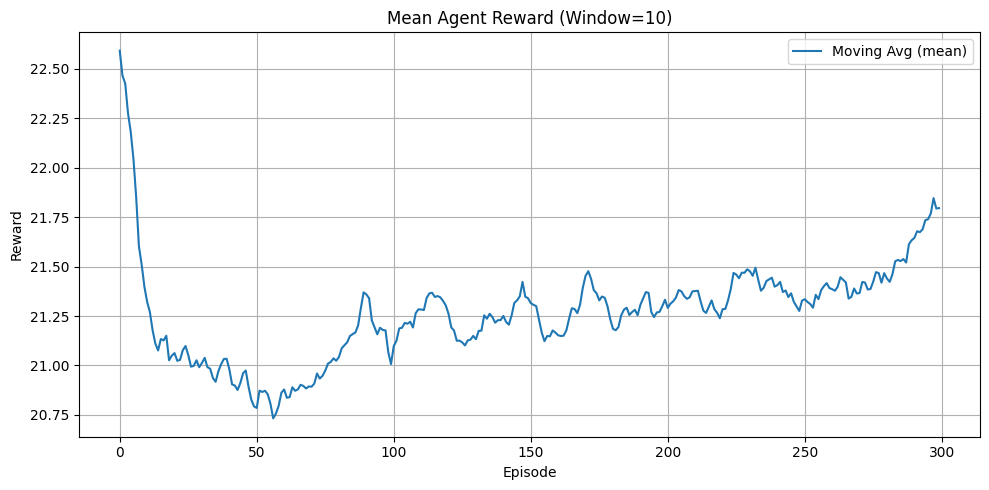

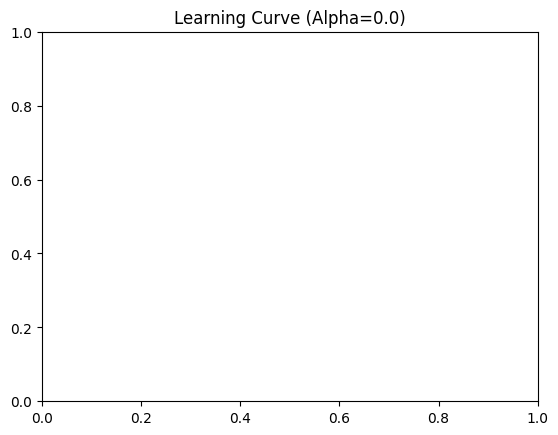

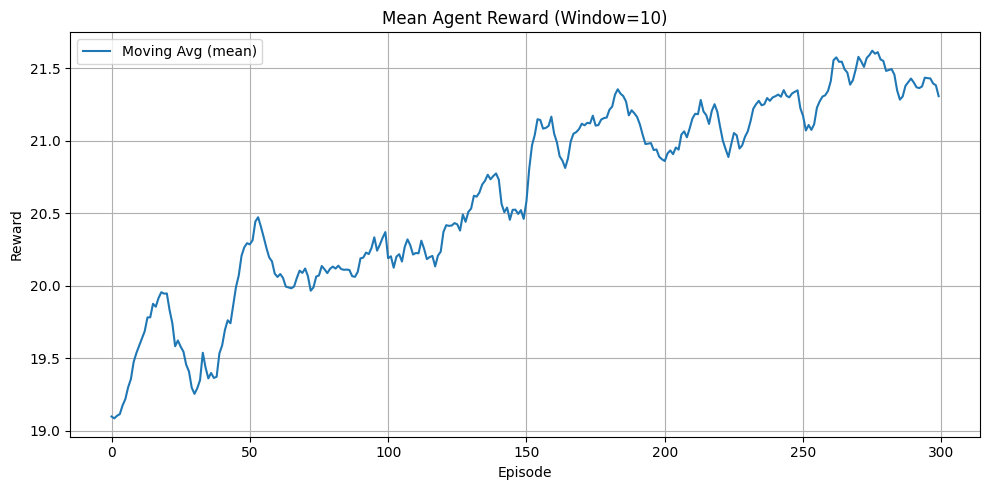

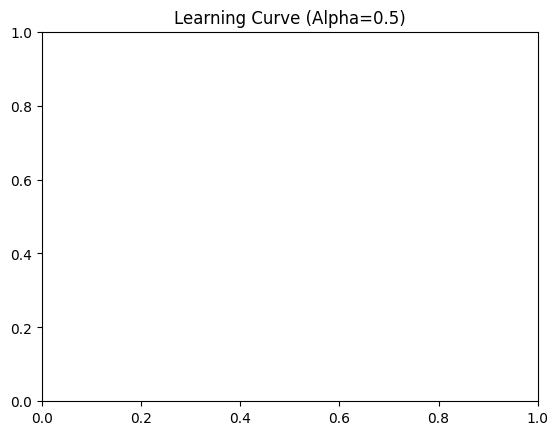

In [15]:
# --- Learning curve analysis ---
if 'df_graph_summary' in locals() and len(df_graph_summary) > 0:
    if 'alpha' in df_graph_summary.columns:
        for alpha_val in sorted(df_graph_summary['alpha'].unique()):
            df_filtered = df_graph_summary[df_graph_summary['alpha'] == alpha_val].copy()

            windowed_df = windowed_avg_reward(
                df=df_filtered,
                reward_prefix="total_reward_",
                episode_column="episode",
                simulation_id_column="simulation_number",
                window_size=10,
                aggregation_mode="mean",
                plot=True
            )
            plt.title(f"Learning Curve (Alpha={alpha_val})")
            plt.show()
    else:
        windowed_df = windowed_avg_reward(
            df=df_graph_summary,
            reward_prefix="total_reward_",
            episode_column="episode",
            simulation_id_column="simulation_number",
            window_size=10,
            aggregation_mode="mean",
            plot=True
        )

## Individual metric plots

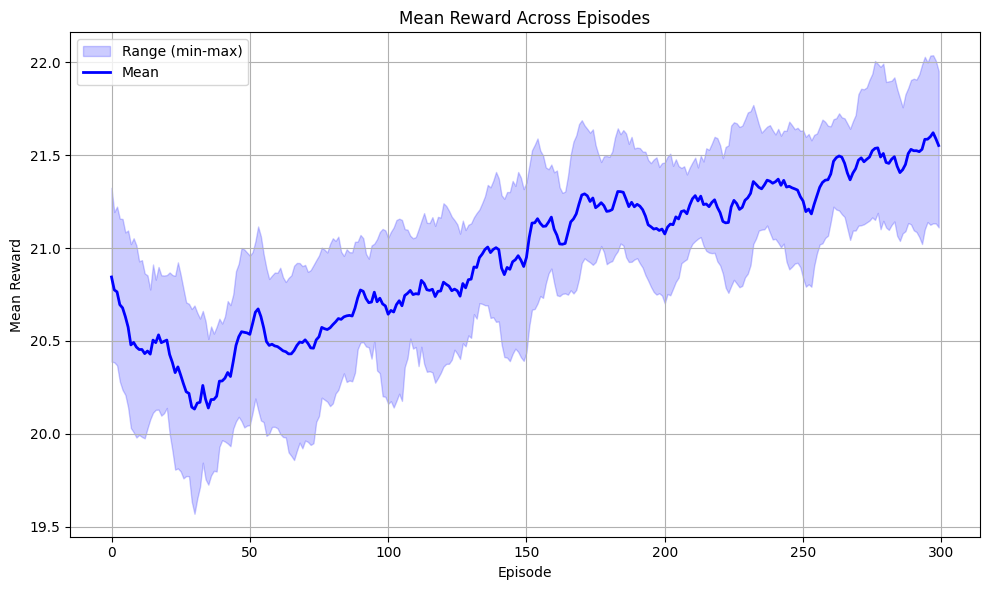

In [16]:
# --- Plot mean reward over episodes ---
if 'df_graph_summary' in locals() and len(df_graph_summary) > 0:
    plot_mean_and_range_across_simulations(
        df=df_graph_summary,
        value_col='mean_reward',
        simulation_col='simulation_number',
        episode_col='episode',
        title='Mean Reward Across Episodes',
        ylabel='Mean Reward',
        rolling_window=10,
        plot_individual=False
    )

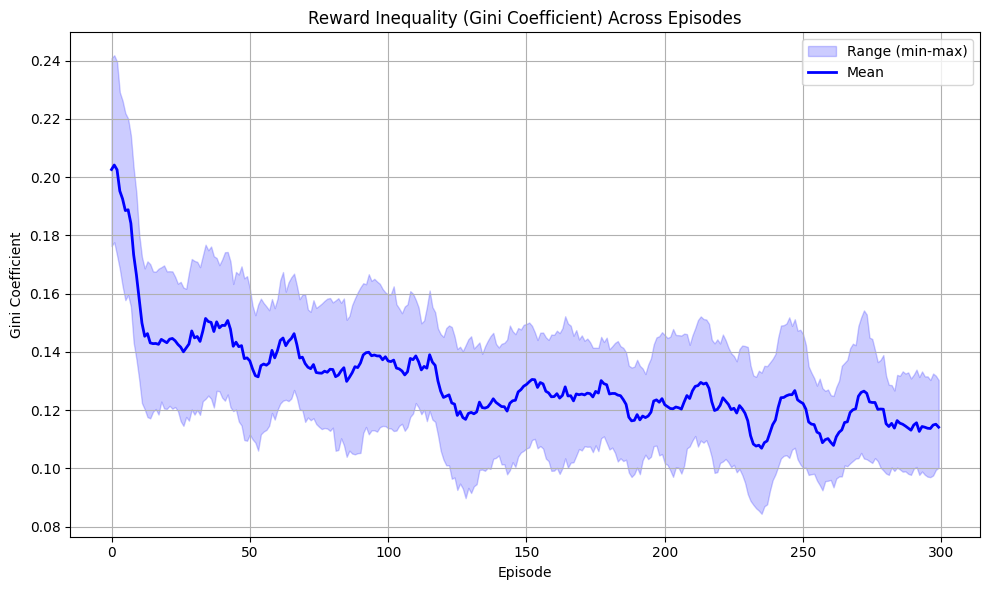

In [17]:
# --- Plot Gini coefficient (inequality) over episodes ---
if 'df_graph_summary' in locals() and len(df_graph_summary) > 0:
    plot_mean_and_range_across_simulations(
        df=df_graph_summary,
        value_col='gini_reward',
        simulation_col='simulation_number',
        episode_col='episode',
        title='Reward Inequality (Gini Coefficient) Across Episodes',
        ylabel='Gini Coefficient',
        rolling_window=10,
        plot_individual=False
    )

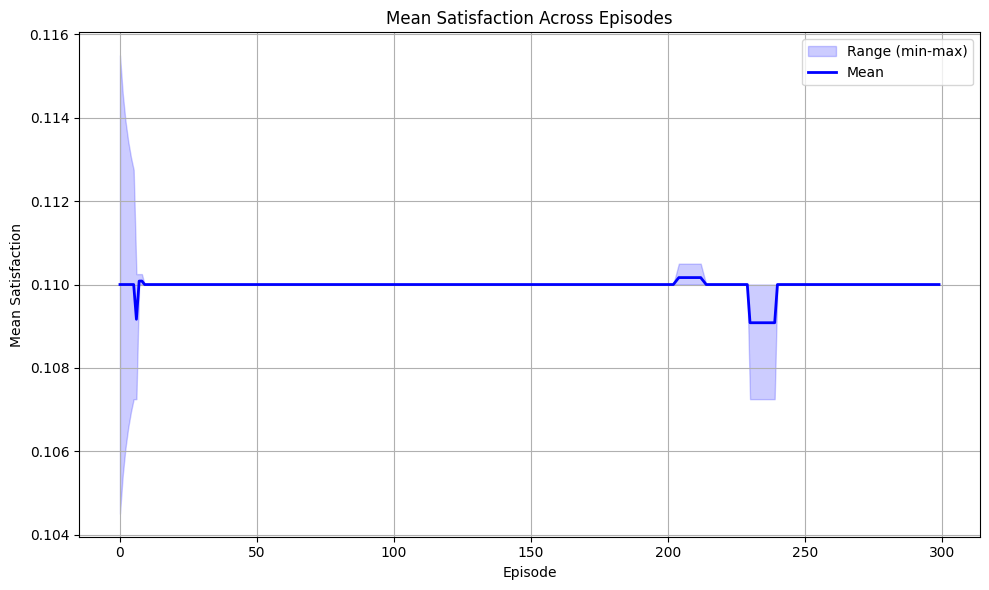

In [18]:
# --- Plot satisfaction over episodes ---
if 'df_graph_summary' in locals() and len(df_graph_summary) > 0:
    plot_mean_and_range_across_simulations(
        df=df_graph_summary,
        value_col='mean_satisfaction',
        simulation_col='simulation_number',
        episode_col='episode',
        title='Mean Satisfaction Across Episodes',
        ylabel='Mean Satisfaction',
        rolling_window=10,
        plot_individual=False
    )

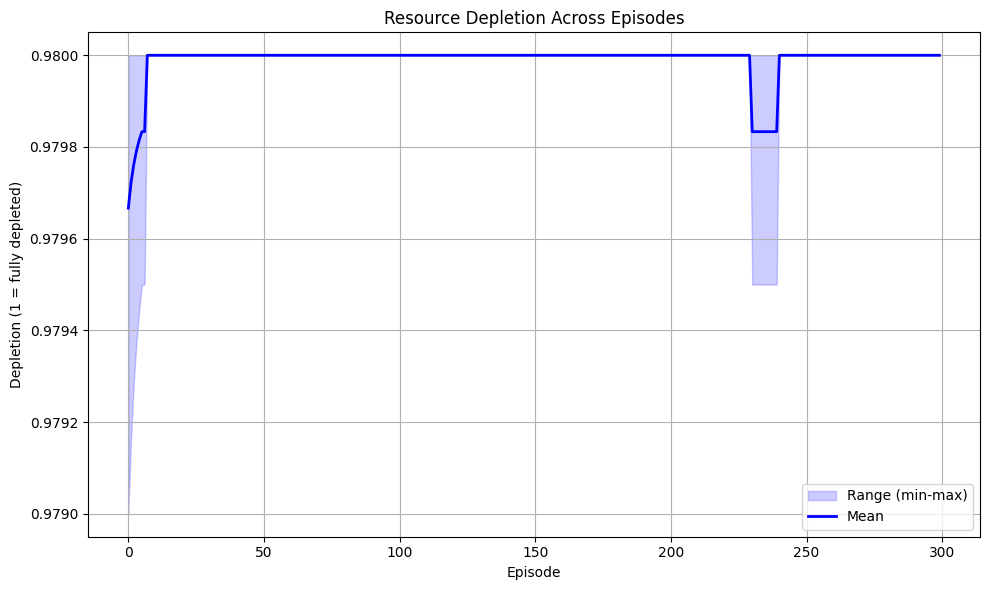

In [19]:
# --- Plot resource depletion over episodes ---
if 'df_graph_summary' in locals() and len(df_graph_summary) > 0:
    plot_mean_and_range_across_simulations(
        df=df_graph_summary,
        value_col='depletion_final',
        simulation_col='simulation_number',
        episode_col='episode',
        title='Resource Depletion Across Episodes',
        ylabel='Depletion (1 = fully depleted)',
        rolling_window=10,
        plot_individual=False
    )

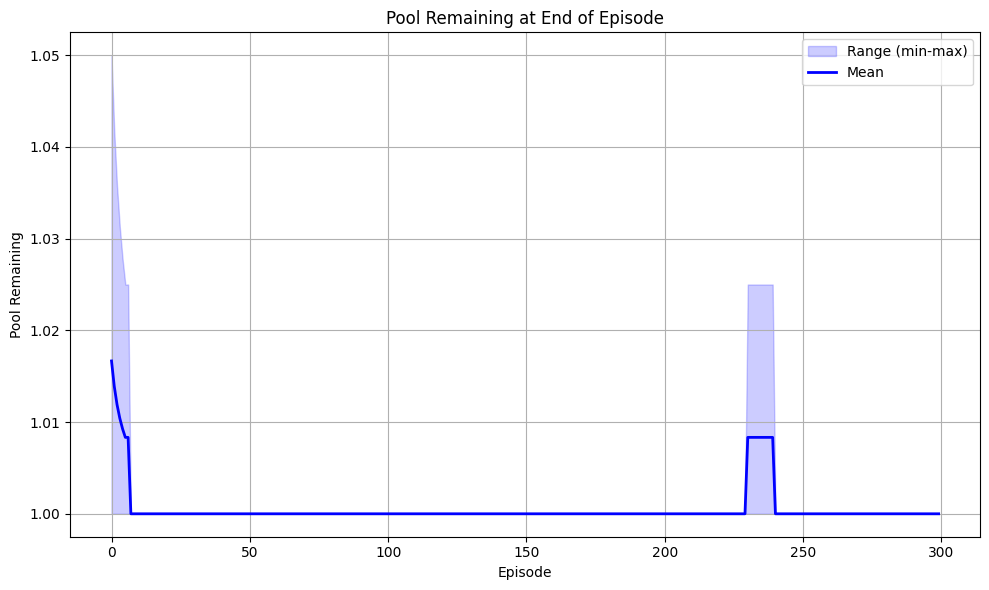

In [20]:
# --- Plot pool remaining at end of episode ---
if 'df_graph_summary' in locals() and len(df_graph_summary) > 0:
    plot_mean_and_range_across_simulations(
        df=df_graph_summary,
        value_col='pool_remaining',
        simulation_col='simulation_number',
        episode_col='episode',
        title='Pool Remaining at End of Episode',
        ylabel='Pool Remaining',
        rolling_window=10,
        plot_individual=False
    )

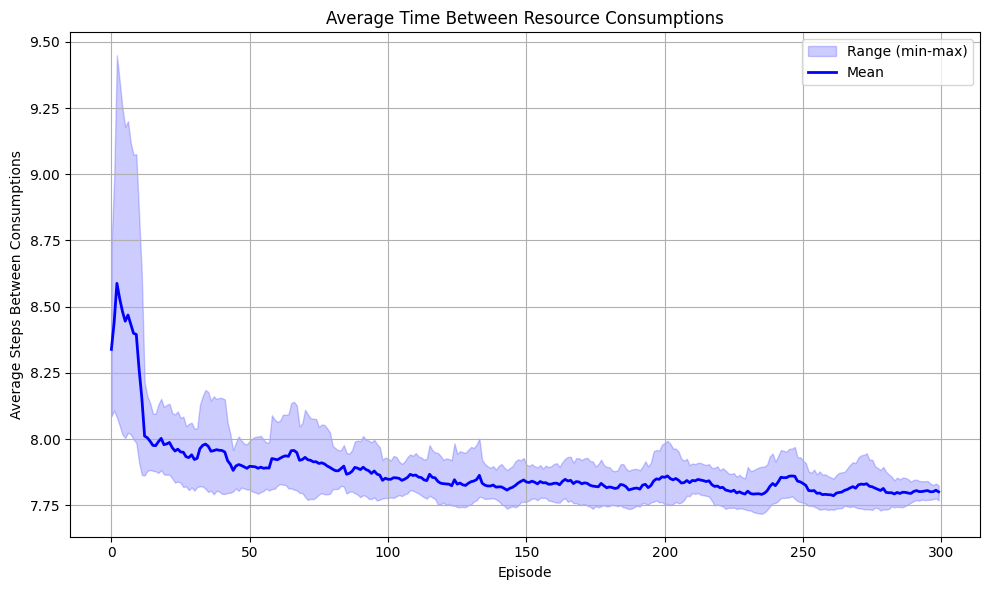

In [21]:
# --- Plot average time between consumptions ---
if 'df_graph_summary' in locals() and len(df_graph_summary) > 0:
    if 'avg_time_between_consumptions' in df_graph_summary.columns:
        plot_mean_and_range_across_simulations(
            df=df_graph_summary,
            value_col='avg_time_between_consumptions',
            simulation_col='simulation_number',
            episode_col='episode',
            title='Average Time Between Resource Consumptions',
            ylabel='Average Steps Between Consumptions',
            rolling_window=10,
            plot_individual=False
        )

## Empathic vs Non-Empathic comparison

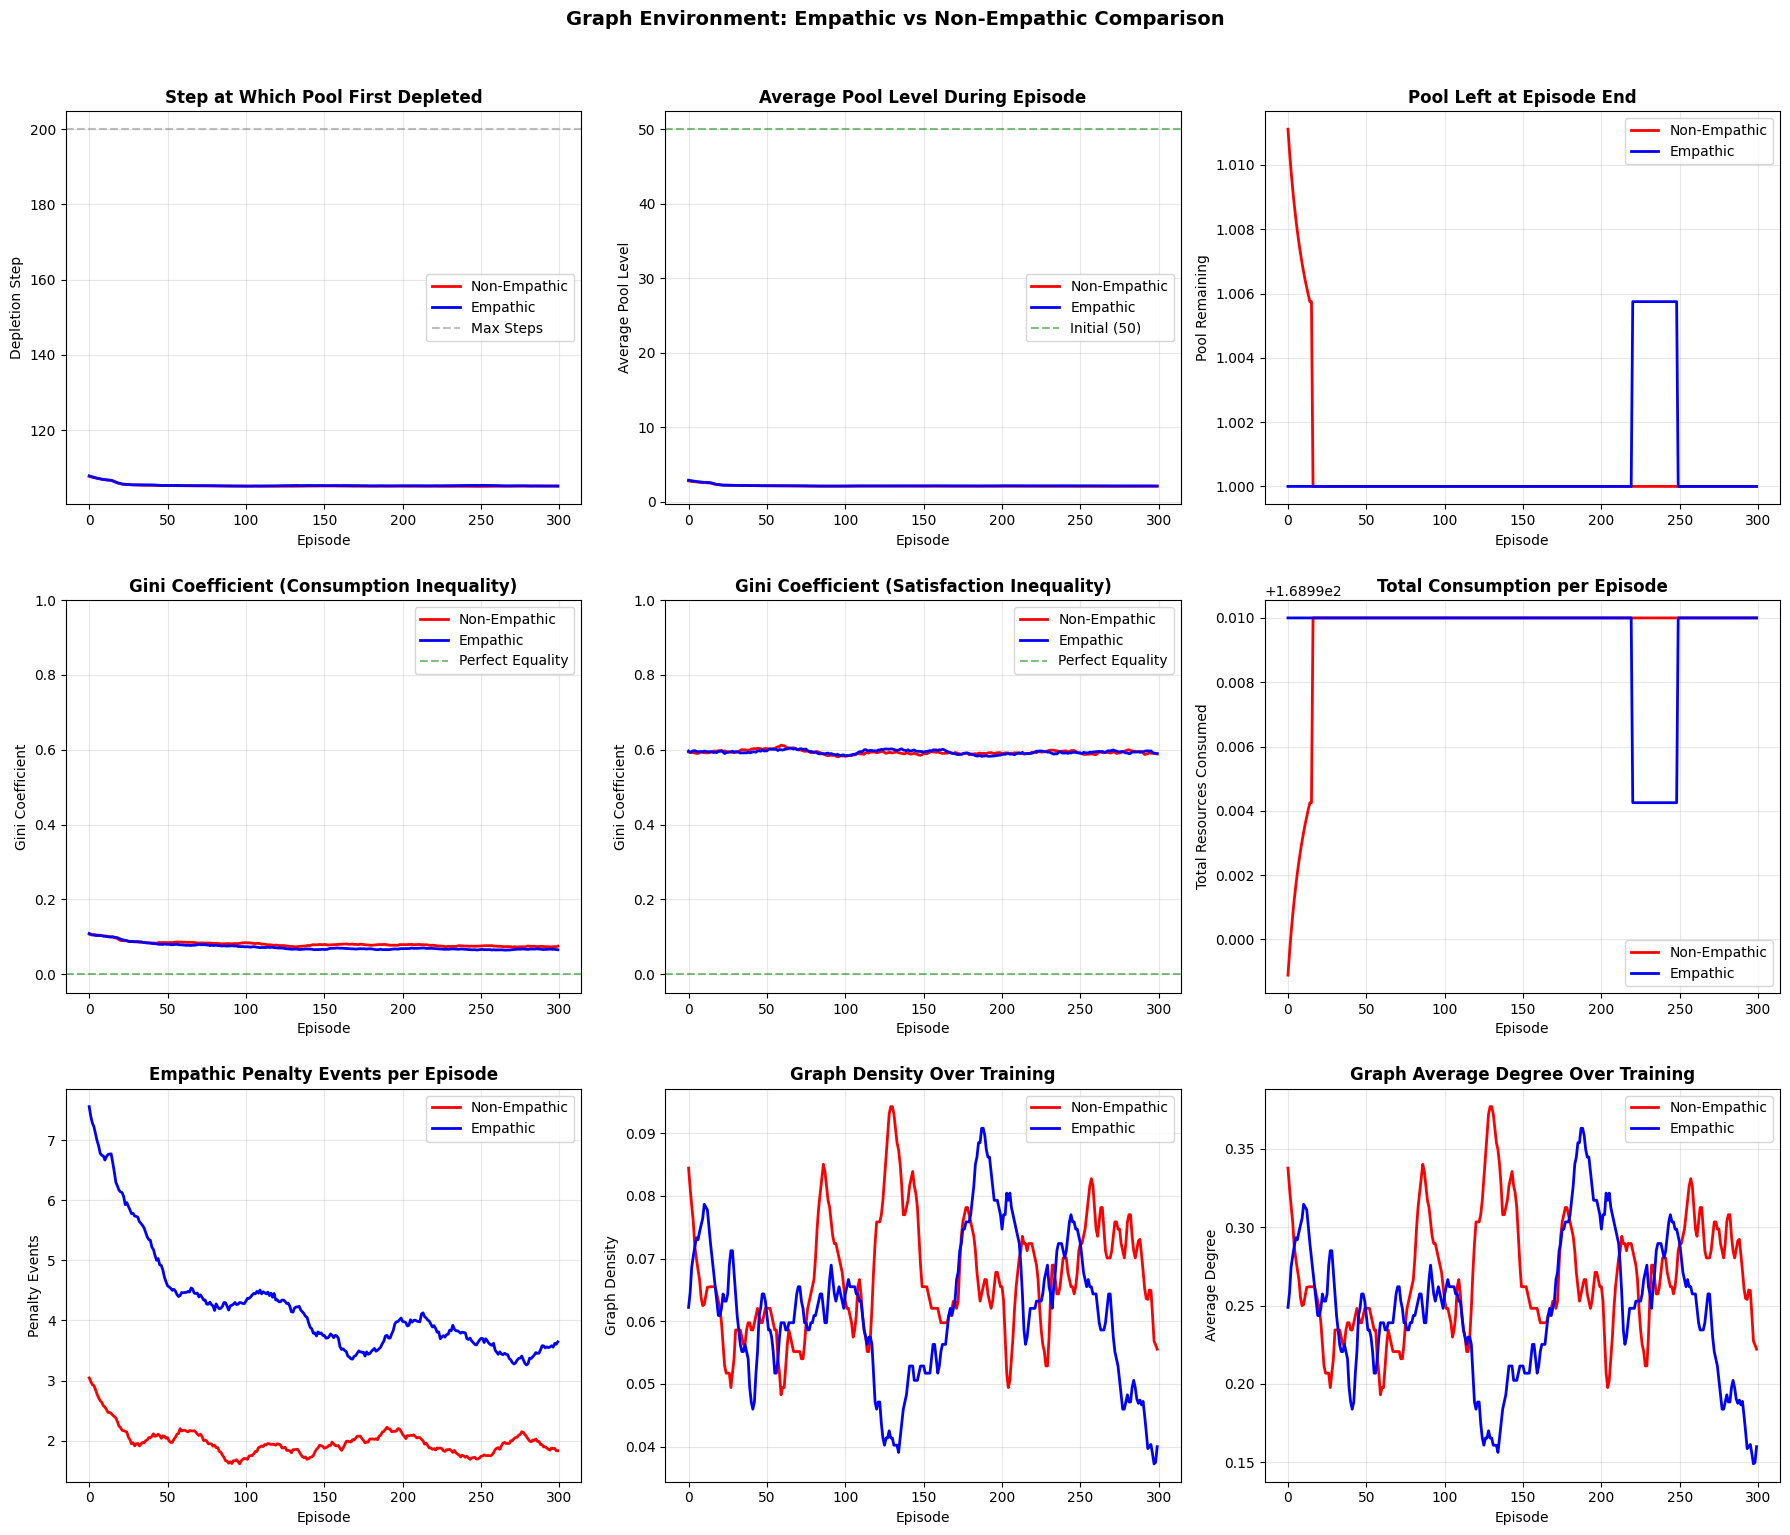


Figure saved as 'empathy_comparison_graph.png'


In [22]:
# --- Empathic vs Non-Empathic Comparison (3x3 grid) ---
if 'df_graph_summary' in locals() and len(df_graph_summary) > 0 and 'alpha' in df_graph_summary.columns:
    agg_dict = {
        'depletion_step': 'mean',
        'pool_remaining': 'mean',
        'avg_pool_during_episode': 'mean',
        'gini_consumption': 'mean',
        'gini_satisfaction': 'mean',
        'total_consumption': 'mean',
        'empathic_penalties_count': 'mean',
        'graph_density': 'mean',
        'graph_avg_degree': 'mean',
    }

    comparison = df_graph_summary.groupby(['episode', 'alpha']).agg(agg_dict).reset_index()

    max_episode = comparison['episode'].max()
    window_size = max(1, int(max_episode / 10))

    max_steps_val = 200
    initial_pool = df_graph_summary['initial_pool'].iloc[0] if 'initial_pool' in df_graph_summary.columns else 50

    fig, axes = plt.subplots(3, 3, figsize=(18, 15))

    for alpha_val in sorted(comparison['alpha'].unique()):
        data = comparison[comparison['alpha'] == alpha_val].copy()
        data = data.sort_values('episode')

        for col in agg_dict.keys():
            if col in data.columns:
                data[f'{col}_smooth'] = data[col].rolling(window=window_size, min_periods=1, center=True).mean()

        if alpha_val > 0:
            label = 'Empathic'
            color = 'blue'
        else:
            label = 'Non-Empathic'
            color = 'red'

        # Row 1: Resource-related metrics
        axes[0, 0].plot(data['episode'], data['depletion_step_smooth'], label=label, color=color, linewidth=2)
        axes[0, 1].plot(data['episode'], data['avg_pool_during_episode_smooth'], label=label, color=color, linewidth=2)
        axes[0, 2].plot(data['episode'], data['pool_remaining_smooth'], label=label, color=color, linewidth=2)

        # Row 2: Inequality and consumption metrics
        axes[1, 0].plot(data['episode'], data['gini_consumption_smooth'], label=label, color=color, linewidth=2)
        axes[1, 1].plot(data['episode'], data['gini_satisfaction_smooth'], label=label, color=color, linewidth=2)
        axes[1, 2].plot(data['episode'], data['total_consumption_smooth'], label=label, color=color, linewidth=2)

        # Row 3: Empathic penalties and graph structure
        axes[2, 0].plot(data['episode'], data['empathic_penalties_count_smooth'], label=label, color=color, linewidth=2)
        axes[2, 1].plot(data['episode'], data['graph_density_smooth'], label=label, color=color, linewidth=2)
        axes[2, 2].plot(data['episode'], data['graph_avg_degree_smooth'], label=label, color=color, linewidth=2)

    # Configure axes - Row 1
    axes[0, 0].axhline(y=max_steps_val, color='gray', linestyle='--', alpha=0.5, label='Max Steps')
    axes[0, 0].set_xlabel('Episode')
    axes[0, 0].set_ylabel('Depletion Step')
    axes[0, 0].set_title('Step at Which Pool First Depleted', fontweight='bold')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)

    axes[0, 1].axhline(y=initial_pool, color='green', linestyle='--', alpha=0.5, label=f'Initial ({int(initial_pool)})')
    axes[0, 1].set_xlabel('Episode')
    axes[0, 1].set_ylabel('Average Pool Level')
    axes[0, 1].set_title('Average Pool Level During Episode', fontweight='bold')
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3)

    axes[0, 2].set_xlabel('Episode')
    axes[0, 2].set_ylabel('Pool Remaining')
    axes[0, 2].set_title('Pool Left at Episode End', fontweight='bold')
    axes[0, 2].legend()
    axes[0, 2].grid(True, alpha=0.3)

    # Configure axes - Row 2
    axes[1, 0].axhline(y=0, color='green', linestyle='--', alpha=0.5, label='Perfect Equality')
    axes[1, 0].set_xlabel('Episode')
    axes[1, 0].set_ylabel('Gini Coefficient')
    axes[1, 0].set_title('Gini Coefficient (Consumption Inequality)', fontweight='bold')
    axes[1, 0].set_ylim(-0.05, 1.0)
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)

    axes[1, 1].axhline(y=0, color='green', linestyle='--', alpha=0.5, label='Perfect Equality')
    axes[1, 1].set_xlabel('Episode')
    axes[1, 1].set_ylabel('Gini Coefficient')
    axes[1, 1].set_title('Gini Coefficient (Satisfaction Inequality)', fontweight='bold')
    axes[1, 1].set_ylim(-0.05, 1.0)
    axes[1, 1].legend()
    axes[1, 1].grid(True, alpha=0.3)

    axes[1, 2].set_xlabel('Episode')
    axes[1, 2].set_ylabel('Total Resources Consumed')
    axes[1, 2].set_title('Total Consumption per Episode', fontweight='bold')
    axes[1, 2].legend()
    axes[1, 2].grid(True, alpha=0.3)

    # Configure axes - Row 3
    axes[2, 0].set_xlabel('Episode')
    axes[2, 0].set_ylabel('Penalty Events')
    axes[2, 0].set_title('Empathic Penalty Events per Episode', fontweight='bold')
    axes[2, 0].legend()
    axes[2, 0].grid(True, alpha=0.3)

    axes[2, 1].set_xlabel('Episode')
    axes[2, 1].set_ylabel('Graph Density')
    axes[2, 1].set_title('Graph Density Over Training', fontweight='bold')
    axes[2, 1].legend()
    axes[2, 1].grid(True, alpha=0.3)

    axes[2, 2].set_xlabel('Episode')
    axes[2, 2].set_ylabel('Average Degree')
    axes[2, 2].set_title('Graph Average Degree Over Training', fontweight='bold')
    axes[2, 2].legend()
    axes[2, 2].grid(True, alpha=0.3)

    plt.suptitle('Graph Environment: Empathic vs Non-Empathic Comparison', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig('empathy_comparison_graph.png', dpi=150, bbox_inches='tight')
    plt.show()

    print("\nFigure saved as 'empathy_comparison_graph.png'")

## Detailed comparison (3x3 grid - rewards, consumption, timing)

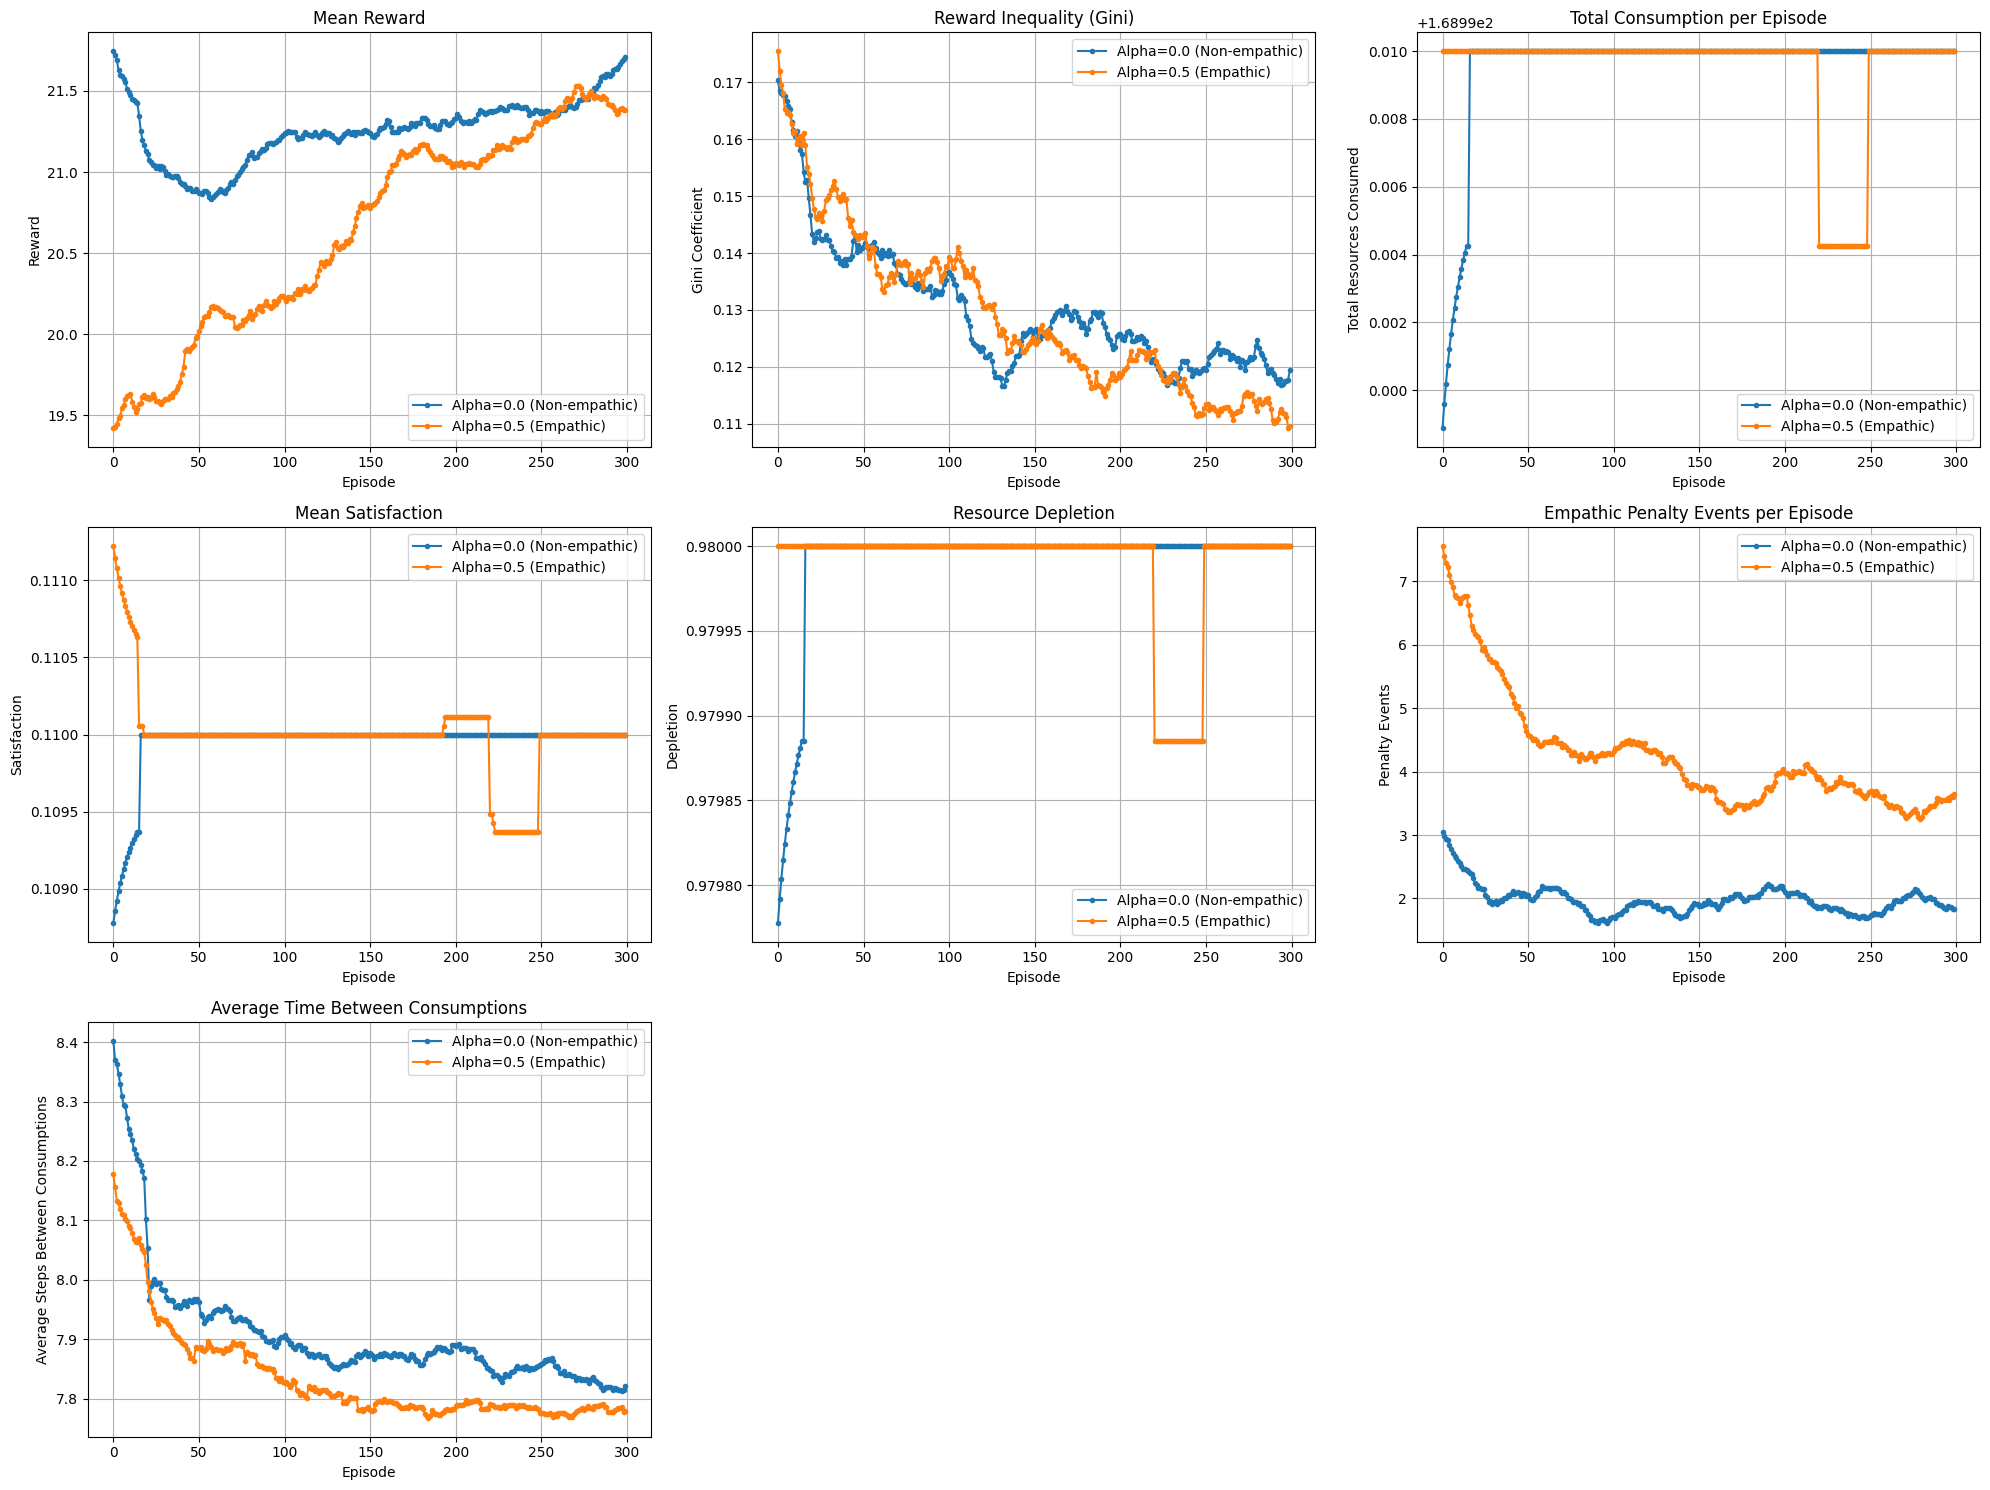

In [23]:
# --- Detailed comparison with reward and timing metrics ---
if 'df_graph_summary' in locals() and len(df_graph_summary) > 0 and 'alpha' in df_graph_summary.columns:
    comparison2 = df_graph_summary.groupby(['episode', 'alpha']).agg({
        'mean_reward': 'mean',
        'gini_reward': 'mean',
        'total_consumption': 'mean',
        'mean_satisfaction': 'mean',
        'depletion_final': 'mean',
        'empathic_penalties_count': 'mean',
        'avg_time_between_consumptions': 'mean',
    }).reset_index()

    max_episode = comparison2['episode'].max()
    window_size = max(1, int(max_episode / 10))

    fig, axes = plt.subplots(3, 3, figsize=(20, 15))

    for alpha_val in sorted(comparison2['alpha'].unique()):
        data = comparison2[comparison2['alpha'] == alpha_val].copy()
        data = data.sort_values('episode')

        data['mean_reward_smooth'] = data['mean_reward'].rolling(window=window_size, min_periods=1, center=True).mean()
        data['gini_reward_smooth'] = data['gini_reward'].rolling(window=window_size, min_periods=1, center=True).mean()
        data['mean_satisfaction_smooth'] = data['mean_satisfaction'].rolling(window=window_size, min_periods=1, center=True).mean()
        data['depletion_final_smooth'] = data['depletion_final'].rolling(window=window_size, min_periods=1, center=True).mean()
        data['avg_time_between_consumptions_smooth'] = data['avg_time_between_consumptions'].rolling(window=window_size, min_periods=1, center=True).mean()
        data['total_consumption_smooth'] = data['total_consumption'].rolling(window=window_size, min_periods=1, center=True).mean()
        data['empathic_penalties_count_smooth'] = data['empathic_penalties_count'].rolling(window=window_size, min_periods=1, center=True).mean()

        label = f"Alpha={alpha_val} (Empathic)" if alpha_val > 0 else "Alpha=0.0 (Non-empathic)"

        axes[0, 0].plot(data['episode'], data['mean_reward_smooth'], label=label, marker='o', markersize=3)
        axes[0, 1].plot(data['episode'], data['gini_reward_smooth'], label=label, marker='o', markersize=3)
        axes[0, 2].plot(data['episode'], data['total_consumption_smooth'], label=label, marker='o', markersize=3)
        axes[1, 0].plot(data['episode'], data['mean_satisfaction_smooth'], label=label, marker='o', markersize=3)
        axes[1, 1].plot(data['episode'], data['depletion_final_smooth'], label=label, marker='o', markersize=3)
        axes[1, 2].plot(data['episode'], data['empathic_penalties_count_smooth'], label=label, marker='o', markersize=3)
        axes[2, 0].plot(data['episode'], data['avg_time_between_consumptions_smooth'], label=label, marker='o', markersize=3)

    axes[0, 0].set_title('Mean Reward')
    axes[0, 0].set_xlabel('Episode')
    axes[0, 0].set_ylabel('Reward')
    axes[0, 0].legend()
    axes[0, 0].grid(True)

    axes[0, 1].set_title('Reward Inequality (Gini)')
    axes[0, 1].set_xlabel('Episode')
    axes[0, 1].set_ylabel('Gini Coefficient')
    axes[0, 1].legend()
    axes[0, 1].grid(True)

    axes[0, 2].set_title('Total Consumption per Episode')
    axes[0, 2].set_xlabel('Episode')
    axes[0, 2].set_ylabel('Total Resources Consumed')
    axes[0, 2].legend()
    axes[0, 2].grid(True)

    axes[1, 0].set_title('Mean Satisfaction')
    axes[1, 0].set_xlabel('Episode')
    axes[1, 0].set_ylabel('Satisfaction')
    axes[1, 0].legend()
    axes[1, 0].grid(True)

    axes[1, 1].set_title('Resource Depletion')
    axes[1, 1].set_xlabel('Episode')
    axes[1, 1].set_ylabel('Depletion')
    axes[1, 1].legend()
    axes[1, 1].grid(True)

    axes[1, 2].set_title('Empathic Penalty Events per Episode')
    axes[1, 2].set_xlabel('Episode')
    axes[1, 2].set_ylabel('Penalty Events')
    axes[1, 2].legend()
    axes[1, 2].grid(True)

    axes[2, 0].set_title('Average Time Between Consumptions')
    axes[2, 0].set_xlabel('Episode')
    axes[2, 0].set_ylabel('Average Steps Between Consumptions')
    axes[2, 0].legend()
    axes[2, 0].grid(True)

    # Hide unused subplots
    axes[2, 1].axis('off')
    axes[2, 2].axis('off')

    plt.tight_layout()
    plt.show()

## Summary statistics

In [24]:
# --- Summary statistics per condition ---
def print_summary(name, data):
    """Print summary statistics for a condition."""
    print(f"\n{'='*50}")
    print(f"{name}")
    print(f"{'='*50}")
    print(f"Depletion Step:             {data['depletion_step'].mean():.1f} +/- {data['depletion_step'].std():.1f}")
    print(f"Pool Remaining:             {data['pool_remaining'].mean():.2f} +/- {data['pool_remaining'].std():.2f}")
    print(f"Avg Pool During Ep:         {data['avg_pool_during_episode'].mean():.2f} +/- {data['avg_pool_during_episode'].std():.2f}")
    print(f"Total Consumption:          {data['total_consumption'].mean():.1f} +/- {data['total_consumption'].std():.1f}")
    print(f"Gini (Consumption):         {data['gini_consumption'].mean():.3f} +/- {data['gini_consumption'].std():.3f}")
    print(f"Gini (Satisfaction):        {data['gini_satisfaction'].mean():.3f} +/- {data['gini_satisfaction'].std():.3f}")
    print(f"Graph Density:              {data['graph_density'].mean():.3f} +/- {data['graph_density'].std():.3f}")
    print(f"Graph Avg Degree:           {data['graph_avg_degree'].mean():.2f} +/- {data['graph_avg_degree'].std():.2f}")
    print(f"Empathic Penalty Events:    {data['empathic_penalties_count'].mean():.1f} +/- {data['empathic_penalties_count'].std():.1f}")
    if 'mean_reward' in data.columns:
        print(f"Mean Reward:                {data['mean_reward'].mean():.3f} +/- {data['mean_reward'].std():.3f}")
    if 'mean_satisfaction' in data.columns:
        print(f"Mean Satisfaction:          {data['mean_satisfaction'].mean():.3f} +/- {data['mean_satisfaction'].std():.3f}")


if 'df_graph_summary' in locals() and len(df_graph_summary) > 0:
    for alpha in sorted(df_graph_summary['alpha'].unique()):
        condition_name = 'EMPATHIC AGENTS (alpha=0.5)' if alpha > 0 else 'NON-EMPATHIC AGENTS (alpha=0.0)'
        print_summary(condition_name, df_graph_summary[df_graph_summary['alpha'] == alpha])


NON-EMPATHIC AGENTS (alpha=0.0)
Depletion Step:             105.3 +/- 94.7
Pool Remaining:             1.00 +/- 0.02
Avg Pool During Ep:         2.13 +/- 0.60
Total Consumption:          169.0 +/- 80.0
Gini (Consumption):         0.081 +/- 0.034
Gini (Satisfaction):        0.593 +/- 0.092
Graph Density:              0.067 +/- 0.076
Graph Avg Degree:           0.27 +/- 0.30
Empathic Penalty Events:    2.0 +/- 2.5
Mean Reward:                21.267 +/- 11.178
Mean Satisfaction:          0.110 +/- 0.090

EMPATHIC AGENTS (alpha=0.5)
Depletion Step:             105.4 +/- 94.6
Pool Remaining:             1.00 +/- 0.02
Avg Pool During Ep:         2.17 +/- 0.63
Total Consumption:          169.0 +/- 80.0
Gini (Consumption):         0.074 +/- 0.032
Gini (Satisfaction):        0.594 +/- 0.093
Graph Density:              0.062 +/- 0.076
Graph Avg Degree:           0.25 +/- 0.31
Empathic Penalty Events:    4.3 +/- 3.5
Mean Reward:                20.637 +/- 10.936
Mean Satisfaction:          0.110 

## Statistical comparison (Last N Episodes)

In [25]:
# --- Statistical Comparison (Last N Episodes) ---
last_n = 20

if 'df_graph_summary' in locals() and len(df_graph_summary) > 0 and 'alpha' in df_graph_summary.columns:
    max_episode = df_graph_summary['episode'].max()
    last_episodes = df_graph_summary[df_graph_summary['episode'] > max_episode - last_n]

    print(f"{'='*60}")
    print(f"STATISTICAL COMPARISON (Last {last_n} Episodes)")
    print(f"{'='*60}")

    def compare_metric(name, metric_col):
        """Compare a metric between empathic and non-empathic conditions."""
        ne_data = last_episodes[last_episodes['alpha'] == 0.0][metric_col].dropna()
        e_data = last_episodes[last_episodes['alpha'] > 0][metric_col].dropna()

        if len(ne_data) == 0 or len(e_data) == 0:
            print(f"\n{name}: Insufficient data")
            return

        ne_mean, ne_std = np.mean(ne_data), np.std(ne_data)
        e_mean, e_std = np.mean(e_data), np.std(e_data)

        try:
            stat, p_value = stats.mannwhitneyu(ne_data, e_data, alternative='two-sided')
            sig = ""
            if p_value < 0.05: sig = "*"
            if p_value < 0.01: sig = "**"
            if p_value < 0.001: sig = "***"
        except:
            p_value = 1.0
            sig = ""

        pct_change = (e_mean - ne_mean) / (abs(ne_mean) + 1e-6) * 100

        print(f"\n{name}:")
        print(f"  Non-Empathic: {ne_mean:.3f} +/- {ne_std:.3f}")
        print(f"  Empathic:     {e_mean:.3f} +/- {e_std:.3f}")
        print(f"  Difference:   {e_mean - ne_mean:+.3f} ({pct_change:+.1f}%)")
        print(f"  p-value:      {p_value:.4f} {sig}")

    compare_metric("Depletion Step", "depletion_step")
    compare_metric("Pool Remaining", "pool_remaining")
    compare_metric("Avg Pool During Episode", "avg_pool_during_episode")
    compare_metric("Gini (Consumption)", "gini_consumption")
    compare_metric("Gini (Satisfaction)", "gini_satisfaction")
    compare_metric("Total Consumption", "total_consumption")
    compare_metric("Graph Density", "graph_density")
    compare_metric("Graph Avg Degree", "graph_avg_degree")
    compare_metric("Empathic Penalty Events", "empathic_penalties_count")
    compare_metric("Mean Reward", "mean_reward")
    compare_metric("Mean Satisfaction", "mean_satisfaction")

    print(f"\n{'='*60}")
    print("Significance: * p<0.05, ** p<0.01, *** p<0.001")
    print(f"{'='*60}")

STATISTICAL COMPARISON (Last 20 Episodes)

Depletion Step:
  Non-Empathic: 105.158 +/- 94.843
  Empathic:     105.167 +/- 94.834
  Difference:   +0.008 (+0.0%)
  p-value:      0.9542 

Pool Remaining:
  Non-Empathic: 1.000 +/- 0.000
  Empathic:     1.000 +/- 0.000
  Difference:   +0.000 (+0.0%)
  p-value:      1.0000 

Avg Pool During Episode:
  Non-Empathic: 2.077 +/- 0.534
  Empathic:     2.125 +/- 0.594
  Difference:   +0.047 (+2.3%)
  p-value:      0.1401 

Gini (Consumption):
  Non-Empathic: 0.073 +/- 0.026
  Empathic:     0.067 +/- 0.026
  Difference:   -0.006 (-8.6%)
  p-value:      0.0859 

Gini (Satisfaction):
  Non-Empathic: 0.592 +/- 0.097
  Empathic:     0.596 +/- 0.092
  Difference:   +0.005 (+0.8%)
  p-value:      0.5161 

Total Consumption:
  Non-Empathic: 169.000 +/- 80.000
  Empathic:     169.000 +/- 80.000
  Difference:   +0.000 (+0.0%)
  p-value:      1.0000 

Graph Density:
  Non-Empathic: 0.065 +/- 0.073
  Empathic:     0.040 +/- 0.066
  Difference:   -0.025 (-38.5

## Distribution analysis (Final Episodes)

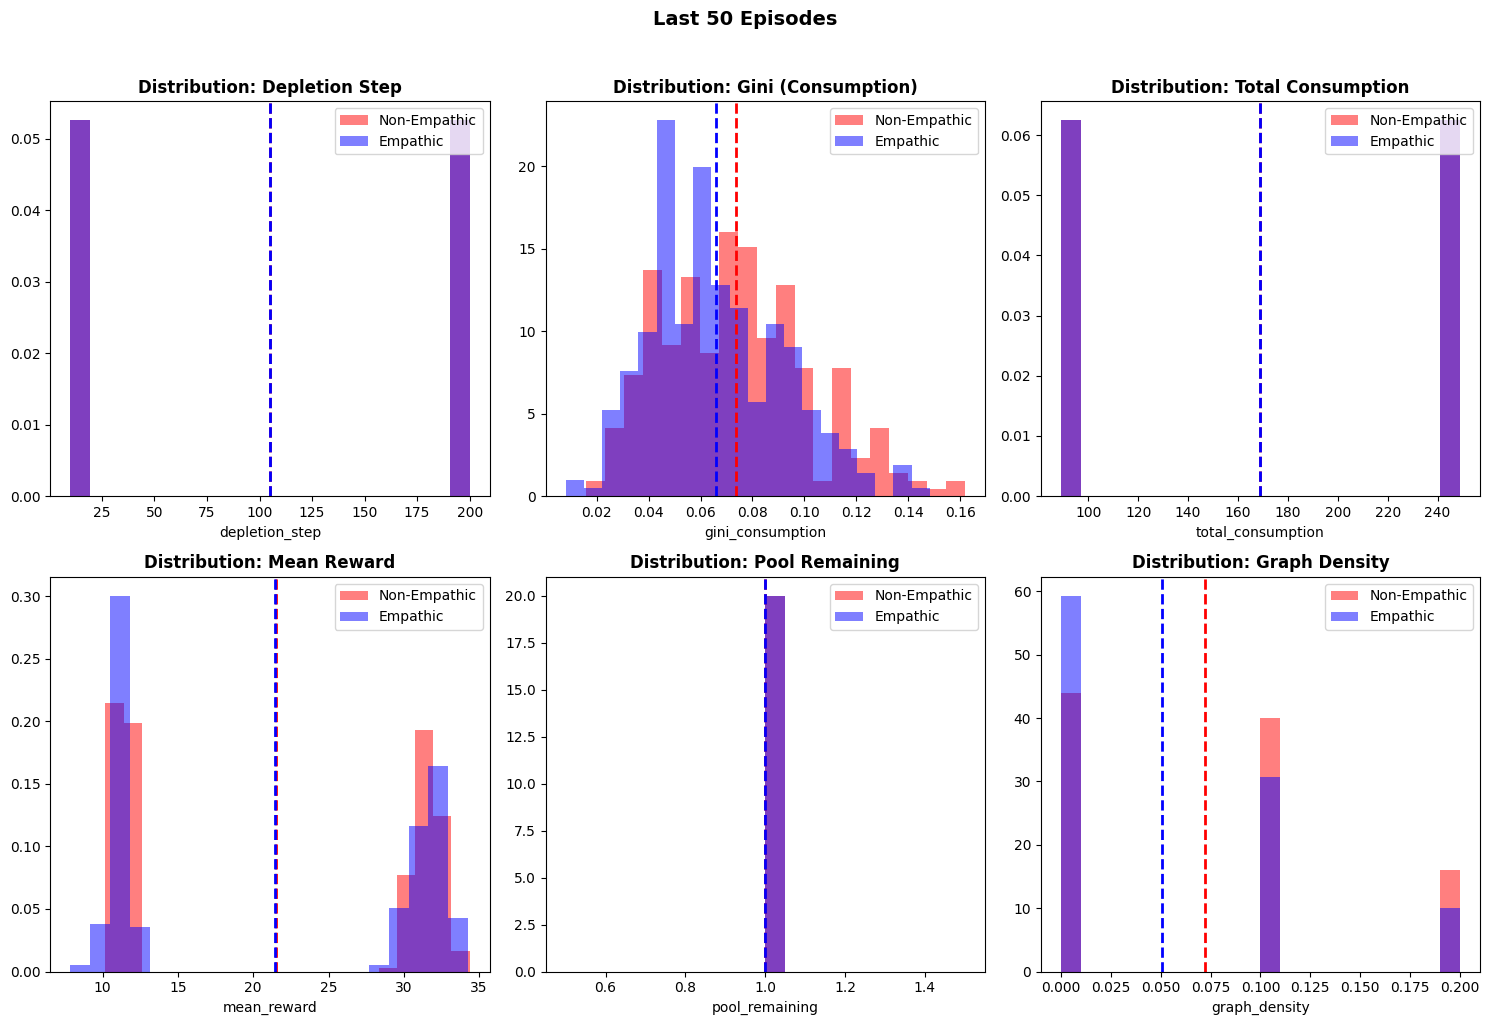

In [26]:
# --- Distribution Analysis (Last N Episodes) ---
last_n = 50

if 'df_graph_summary' in locals() and len(df_graph_summary) > 0 and 'alpha' in df_graph_summary.columns:
    max_episode = df_graph_summary['episode'].max()
    last_episodes = df_graph_summary[df_graph_summary['episode'] > max_episode - last_n]
    ne_data = last_episodes[last_episodes['alpha'] == 0.0]
    e_data = last_episodes[last_episodes['alpha'] > 0]

    dist_metrics = [
        ('depletion_step', 'Depletion Step'),
        ('gini_consumption', 'Gini (Consumption)'),
        ('total_consumption', 'Total Consumption'),
        ('mean_reward', 'Mean Reward'),
        ('pool_remaining', 'Pool Remaining'),
        ('graph_density', 'Graph Density'),
    ]
    dist_metrics = [(c, t) for c, t in dist_metrics if c in df_graph_summary.columns]
    n_plots = len(dist_metrics)
    n_cols = (n_plots + 1) // 2

    fig, axes = plt.subplots(2, n_cols, figsize=(5 * n_cols, 10))
    axes = np.atleast_1d(axes).flatten()

    for idx, (col, title) in enumerate(dist_metrics):
        ax = axes[idx]
        ax.hist(ne_data[col].dropna(), bins=20, alpha=0.5, color='red', label='Non-Empathic', density=True)
        ax.hist(e_data[col].dropna(), bins=20, alpha=0.5, color='blue', label='Empathic', density=True)
        ax.axvline(ne_data[col].mean(), color='red', linestyle='--', linewidth=2)
        ax.axvline(e_data[col].mean(), color='blue', linestyle='--', linewidth=2)
        ax.set_xlabel(col)
        ax.set_title(f'Distribution: {title}', fontweight='bold')
        ax.legend()

    for j in range(len(dist_metrics), len(axes)):
        axes[j].set_visible(False)

    plt.suptitle(f'Last {last_n} Episodes', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

## Per-Agent analysis (Last N Episodes)

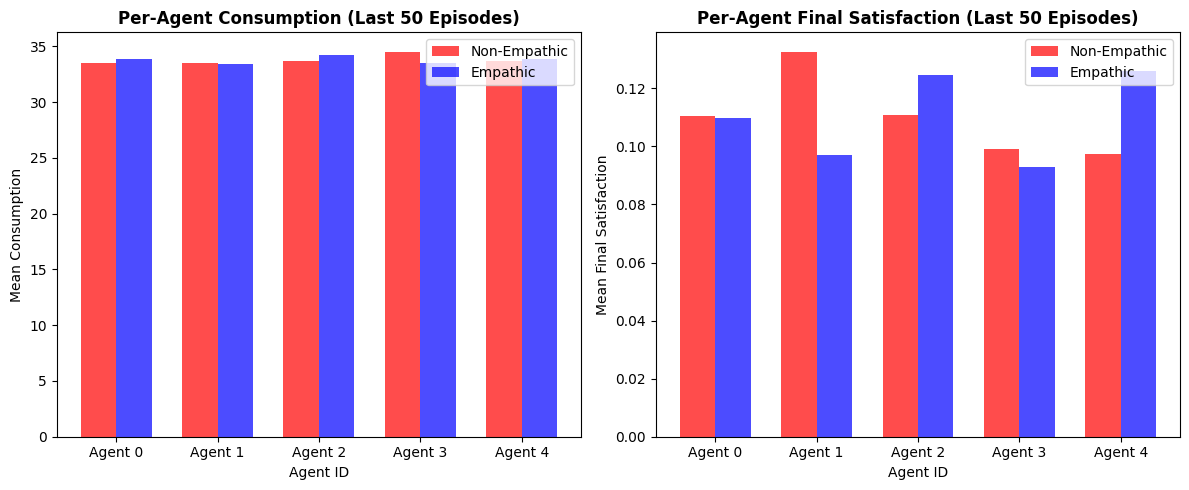

In [27]:
# --- Per-Agent Analysis (Last N Episodes) ---
last_n = 50

if 'df_graph_summary' in locals() and len(df_graph_summary) > 0:
    max_episode = df_graph_summary['episode'].max()
    last_episodes = df_graph_summary[df_graph_summary['episode'] > max_episode - last_n]

    consumption_cols = [c for c in df_graph_summary.columns if c.startswith('consumption_per_agent_')]
    satisfaction_cols = [c for c in df_graph_summary.columns if c.startswith('final_satisfaction_')]

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    if consumption_cols:
        ne_consumption = last_episodes[last_episodes['alpha'] == 0.0][consumption_cols].mean()
        e_consumption = last_episodes[last_episodes['alpha'] > 0][consumption_cols].mean()
        x = np.arange(len(consumption_cols))
        width = 0.35
        axes[0].bar(x - width/2, ne_consumption.values, width, label='Non-Empathic', color='red', alpha=0.7)
        axes[0].bar(x + width/2, e_consumption.values, width, label='Empathic', color='blue', alpha=0.7)
        axes[0].set_xticks(x)
        axes[0].set_xticklabels([f'Agent {i}' for i in range(len(consumption_cols))])
        axes[0].set_xlabel('Agent ID')
        axes[0].set_ylabel('Mean Consumption')
        axes[0].set_title('Per-Agent Consumption (Last 50 Episodes)', fontweight='bold')
        axes[0].legend()

    if satisfaction_cols:
        ne_satisfaction = last_episodes[last_episodes['alpha'] == 0.0][satisfaction_cols].mean()
        e_satisfaction = last_episodes[last_episodes['alpha'] > 0][satisfaction_cols].mean()
        x = np.arange(len(satisfaction_cols))
        width = 0.35
        axes[1].bar(x - width/2, ne_satisfaction.values, width, label='Non-Empathic', color='red', alpha=0.7)
        axes[1].bar(x + width/2, e_satisfaction.values, width, label='Empathic', color='blue', alpha=0.7)
        axes[1].set_xticks(x)
        axes[1].set_xticklabels([f'Agent {i}' for i in range(len(satisfaction_cols))])
        axes[1].set_xlabel('Agent ID')
        axes[1].set_ylabel('Mean Final Satisfaction')
        axes[1].set_title('Per-Agent Final Satisfaction (Last 50 Episodes)', fontweight='bold')
        axes[1].legend()

    plt.tight_layout()
    plt.show()